In [185]:
%matplotlib inline

import matplotlib
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import os

In [41]:
# Load data
def load_data(data_path):
    if os.path.isfile(data_path):
        data = np.genfromtxt(data_path, names=True, delimiter=",")
        return data
    else:
        return None
    
data = load_data("/home/martin/projects/hector/src/whole_body_posture_optimization/whole_body_planning_data/csv/cost_function/flipper_multi_objective_cost_asterix/step1-GT.csv")
x = data["flipper_front_joint"]
y = data["flipper_back_joint"]
z = data["total_cost"]


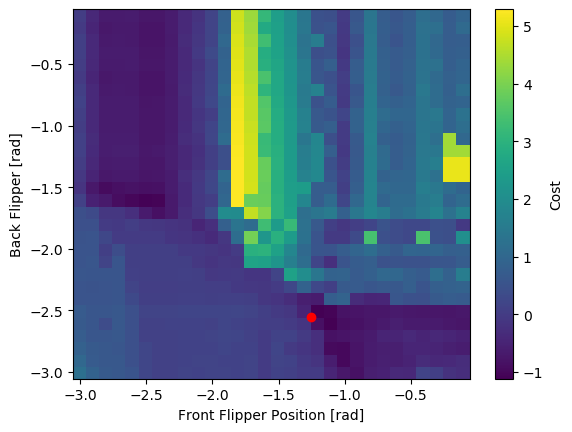

In [180]:
def plot_2d_color_mesh(fig, ax, x, y, z):
    X, Y = np.meshgrid(np.unique(x), np.unique(y))
    Z = np.empty_like(X)

    # Fill the Z array with the corresponding z values based on x and y
    for i in range(len(X)):
        for j in range(len(X[i])):
            mask = (x == X[i, j]) & (y == Y[i, j])
            Z[i, j] = z[mask][0] if np.sum(mask) > 0 else np.nan

    colormesh = ax.pcolormesh(X, Y, Z, cmap='viridis', shading='auto') # gouraud

    # Add colorbar to show the mapping of values to colors
    cbar = fig.colorbar(colormesh)
    cbar.set_label('Cost')

    # Set labels and title
    ax.set_xlabel('Front Flipper Position [rad]')
    ax.set_ylabel('Back Flipper [rad]')
    # plt.title('3D Data in 2D with Colormap using pcolormesh')

def plot_minimum(ax, x, y, z):
    minf = np.minimum.accumulate(data["total_cost"])
    minf_reached = np.where(minf == minf[-1])
    ax.scatter(x=[data["flipper_front_joint"][minf_reached[0][0]]],
            y=[data["flipper_back_joint"][minf_reached[0][0]]],
            color="red",
            marker="o")


fig, ax = plt.subplots(    
    # figsize=(7, 7), 
)

plot_2d_color_mesh(fig, ax, x, y, z)
plot_minimum(ax, x, y, z)

plt.show()





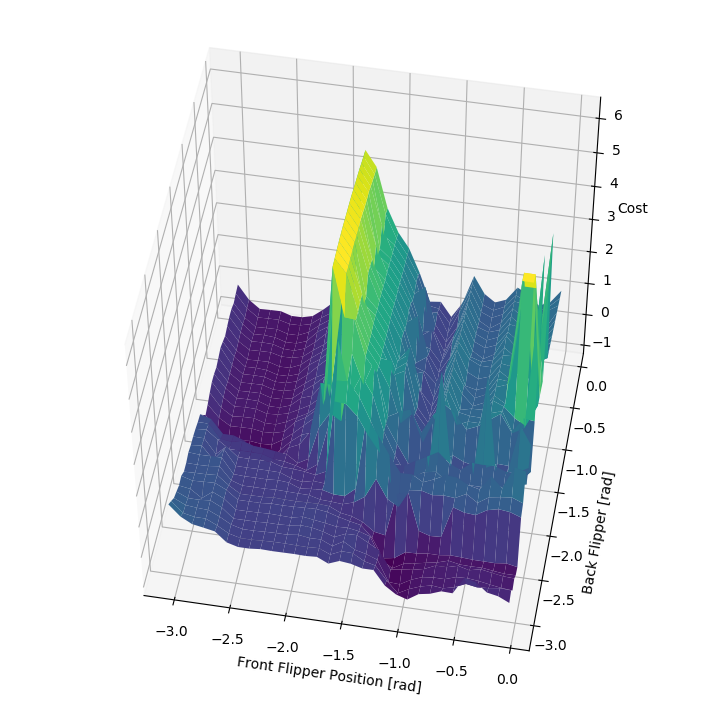

In [186]:
def plot_3d_color_mesh(ax, x, y, z):
    # Create a 2D grid using meshgrid
    X, Y = np.meshgrid(np.unique(x), np.unique(y))

    # Create a 2D array to store the corresponding z values
    Z = np.empty_like(X)

    # Fill the Z array with the corresponding z values based on x and y
    for i in range(len(X)):
        for j in range(len(X[i])):
            mask = (x == X[i, j]) & (y == Y[i, j])
            Z[i, j] = z[mask][0] if np.sum(mask) > 0 else np.nan

    # Plot the colormap using pcolormesh
    ax.plot_surface(X, Y, Z, cmap='viridis', zorder=-1)
    ax.view_init(elev=50, azim=-80)

    # Add colorbar to show the mapping of values to colors
    # cbar = plt.colorbar()
    # cbar.set_label('Cost')

    # Set labels and title
    ax.set_xlabel('Front Flipper Position [rad]')
    ax.set_ylabel('Back Flipper [rad]', labelpad=10)
    ax.set_zlabel("Cost")
    # plt.title('3D Data in 2D with Colormap using pcolormesh')

def plot_minimum_3d(ax, x, y, z):
    minf = np.minimum.accumulate(data["total_cost"])
    minf_reached = np.where(minf == minf[-1])
    ax.scatter(xs=[data["flipper_front_joint"][minf_reached[0][0]]],
            ys=[data["flipper_back_joint"][minf_reached[0][0]]],
            zs=[minf[-1]+3],
            s=1000,
            color="red",
            zorder=4)


_, ax2 = plt.subplots(
    subplot_kw={"projection": "3d"}, 
    figsize=(7, 7), 
    gridspec_kw=dict(top=1.0, bottom=0.0, left=0.0, right=1)
    # constrained_layout=True
    )
# plot_minimum_3d(ax2, x, y, z)
plot_3d_color_mesh(ax2, x, y, z)
plt.subplots_adjust(top=1.0, bottom=0.0, left=0.0, right=1)
# plt.savefig('1.png', bbox_inches='tight')

plt.show()
